<a href="https://colab.research.google.com/github/PritiPojage/NLP/blob/main/POStagging.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ***Implement POS tagging using an existing NLP library such as spaCy and analyze the grammatical category assigned to each token.

In [ ]:
import nltk
import spacy
import pandas as pd

nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger_eng')

nlp = spacy.load("en_core_web_sm")

text = """
       The quick brown fox jumps over the lazy dog.
       Time flies like an arrow; fruit flies like a banana.
       """

doc = nlp(text)
print("\n")
for token in doc:
    print(token.text, "->", token.pos_)

print("\n")
print("Text processed successfully.")
print("Number of tokens:", len(doc))



[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!





        -> SPACE
The -> DET
quick -> ADJ
brown -> ADJ
fox -> NOUN
jumps -> VERB
over -> ADP
the -> DET
lazy -> ADJ
dog -> NOUN
. -> PUNCT

        -> SPACE
Time -> PROPN
flies -> VERB
like -> ADP
an -> DET
arrow -> NOUN
; -> PUNCT
fruit -> NOUN
flies -> NOUN
like -> ADP
a -> DET
banana -> NOUN
. -> PUNCT

        -> SPACE


Text processed successfully.
Number of tokens: 25


# **POS tagging in tables**

In [ ]:
pos_table = pd.DataFrame({
    "Token": [token.text for token in doc],
    "POS": [token.pos_ for token in doc]
})
print( )
print("*******POS Table*****")
print("*"*70)
print(pos_table.to_string(index=False))

detailed_table=pd.DataFrame({
    "Token":[token.text for token in doc],
    "POS":[token.pos_ for token in doc],
    "Tag":[token.tag_ for token in doc],
    "lemma":[token.lemma_ for token in doc]
})
print( )
print("*******POS Tag*****")
print("*"*70)
print(detailed_table.to_string(index=False))


*******POS Table*****
**********************************************************************
    Token   POS
\n        SPACE
      The   DET
    quick   ADJ
    brown   ADJ
      fox  NOUN
    jumps  VERB
     over   ADP
      the   DET
     lazy   ADJ
      dog  NOUN
        . PUNCT
\n        SPACE
     Time PROPN
    flies  VERB
     like   ADP
       an   DET
    arrow  NOUN
        ; PUNCT
    fruit  NOUN
    flies  NOUN
     like   ADP
        a   DET
   banana  NOUN
        . PUNCT
\n        SPACE

*******POS Tag*****
**********************************************************************
    Token   POS Tag     lemma
\n        SPACE _SP \n       
      The   DET  DT       the
    quick   ADJ  JJ     quick
    brown   ADJ  JJ     brown
      fox  NOUN  NN       fox
    jumps  VERB VBZ      jump
     over   ADP  IN      over
      the   DET  DT       the
     lazy   ADJ  JJ      lazy
      dog  NOUN  NN       dog
        . PUNCT   .         .
\n        SPACE _SP \n       
     Tim

# **POS Tag and morphology**

In [ ]:
tokens = nltk.word_tokenize(text)
tags = nltk.pos_tag(tokens)
analysis_table= pd.DataFrame({
    "Token": [token.text for token in doc],
    "POS": [token.pos_ for token in doc],
    "Tag": [token.tag_ for token in doc],
    "Morphology": [token.morph for token in doc]
})
print(analysis_table.to_string(index=False))


    Token   POS Tag                                        Morphology
\n        SPACE _SP                                                ()
      The   DET  DT                      (Definite=Def, PronType=Art)
    quick   ADJ  JJ                                      (Degree=Pos)
    brown   ADJ  JJ                                      (Degree=Pos)
      fox  NOUN  NN                                     (Number=Sing)
    jumps  VERB VBZ (Number=Sing, Person=3, Tense=Pres, VerbForm=Fin)
     over   ADP  IN                                                ()
      the   DET  DT                      (Definite=Def, PronType=Art)
     lazy   ADJ  JJ                                      (Degree=Pos)
      dog  NOUN  NN                                     (Number=Sing)
        . PUNCT   .                                  (PunctType=Peri)
\n        SPACE _SP                                                ()
     Time PROPN NNP                                     (Number=Sing)
    flies  VERB VBZ 

# **Word analysis**

In [ ]:
word_table=pd.DataFrame({

        "Token":[t.text for t in doc if t.is_alpha],
        "Lemma":[t.lemma_ for t in doc if t.is_alpha],
        "POS":[t.pos_ for t in doc if t.is_alpha],
        "Tag":[t.tag_ for t in doc if t.is_alpha]
})
print(word_table.to_string(index=False))

 Token  Lemma   POS Tag
   The    the   DET  DT
 quick  quick   ADJ  JJ
 brown  brown   ADJ  JJ
   fox    fox  NOUN  NN
 jumps   jump  VERB VBZ
  over   over   ADP  IN
   the    the   DET  DT
  lazy   lazy   ADJ  JJ
   dog    dog  NOUN  NN
  Time   Time PROPN NNP
 flies    fly  VERB VBZ
  like   like   ADP  IN
    an     an   DET  DT
 arrow  arrow  NOUN  NN
 fruit  fruit  NOUN  NN
 flies    fly  NOUN NNS
  like   like   ADP  IN
     a      a   DET  DT
banana banana  NOUN  NN


# **Count which grammatical tags occurs frequently**

In [ ]:
pos_counts=(
    analysis_table["POS"]
    .value_counts()
    .reset_index()
    .rename_axis("POS")
    .reset_index(names="Count")
)
print(pos_counts)

   Count    POS  count
0      0   NOUN      6
1      1    DET      4
2      2  SPACE      3
3      3    ADJ      3
4      4    ADP      3
5      5  PUNCT      3
6      6   VERB      2
7      7  PROPN      1


# **Optical visualization**

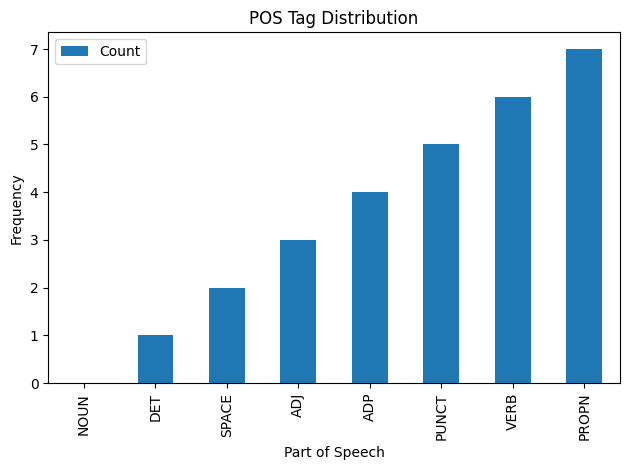

In [ ]:
import matplotlib.pyplot as plt

pos_counts.plot(
kind="bar",
x="POS",
y="Count",
legend=True,
title="POS Tag Distribution"
)

plt.xlabel("Part of Speech")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# **Context-Dependant Tagging**

In [ ]:
sentences=[
    "She runs every morning.",
    "She runs a successful business.",
    "I drink water every day.",
    "Please water the plants.",
    "The cook prepared dinner.",
    "They cook dinner together.",
    "He works in a large building.",
    "They building a new house.",
    "I love the smell of flowers.",
    "Please smell the flowers."
]

for sentence in sentences:
    print("\nSentence:",sentence)
    sentence_doc=nlp(sentence)

    for token in sentence_doc:
          if  token.text.lower() in {"runs","water","cook","building","smell"}:
            print(
                  f" {token.text:10} POS={token.pos_:8} "
                  f"TAG={token.tag_:8} LEMMA={token.lemma_}"
                  )




Sentence: She runs every morning.
 runs       POS=VERB     TAG=VBZ      LEMMA=run

Sentence: She runs a successful business.
 runs       POS=VERB     TAG=VBZ      LEMMA=run

Sentence: I drink water every day.
 water      POS=NOUN     TAG=NN       LEMMA=water

Sentence: Please water the plants.
 water      POS=VERB     TAG=VB       LEMMA=water

Sentence: The cook prepared dinner.
 cook       POS=NOUN     TAG=NN       LEMMA=cook

Sentence: They cook dinner together.
 cook       POS=VERB     TAG=VBP      LEMMA=cook

Sentence: He works in a large building.
 building   POS=NOUN     TAG=NN       LEMMA=building

Sentence: They building a new house.
 building   POS=VERB     TAG=VBG      LEMMA=build

Sentence: I love the smell of flowers.
 smell      POS=NOUN     TAG=NN       LEMMA=smell

Sentence: Please smell the flowers.
 smell      POS=VERB     TAG=VB       LEMMA=smell


# **FINAL TABLE**

In [ ]:
pos_meanings = {
    "NOUN": "Noun",
    "VERB": "Verb",
    "AUX": "Helping Verb",
    "ADJ": "Adjective",
    "ADV": "Adverb",
    "PRON": "Pronoun",
    "DET": "Determiner",
    "ADP": "Preposition",
    "PROPN": "Proper Noun",
    "CCONJ": "Coordinating Conjunction",
    "SCONJ": "Subordinating Conjunction",
    "NUM": "Number",
    "PART": "Particle",
    "INTJ": "Interjection",
    "PUNCT": "Punctuation",
    "SYM": "Symbol",
    "X": "Other"
}

final_table = pd.DataFrame([
      {

      "Token": token.text,
      "Part of Speech": pos_meanings.get(token.pos_, token.pos_),
      "Tag": token.tag_,
      "Base Word": token.lemma_,
      "Morphology": str(token.morph) or "Not applicable"
      }
      for token in doc
      ])

print(final_table.to_string(index=False))

    Token Part of Speech Tag Base Word                                   Morphology
\n                 SPACE _SP \n                                      Not applicable
      The     Determiner  DT       the                    Definite=Def|PronType=Art
    quick      Adjective  JJ     quick                                   Degree=Pos
    brown      Adjective  JJ     brown                                   Degree=Pos
      fox           Noun  NN       fox                                  Number=Sing
    jumps           Verb VBZ      jump Number=Sing|Person=3|Tense=Pres|VerbForm=Fin
     over    Preposition  IN      over                               Not applicable
      the     Determiner  DT       the                    Definite=Def|PronType=Art
     lazy      Adjective  JJ      lazy                                   Degree=Pos
      dog           Noun  NN       dog                                  Number=Sing
        .    Punctuation   .         .                               PunctTy

# **Building the output table**

In [ ]:
rows = []

for token in doc:
    Morphology = str(token.morph) or "Not applicable"

    if token.pos_ == "NOUN":
        if token.morph.get("Number") == ["Plur"]:
            observation = "Plural noun"
        else:
            observation = "Noun"

    elif token.pos_ == "AUX":
        observation = "Auxiliary verb"

    elif token.pos_ == "VERB":
        verb_form = token.morph.get("VerbForm")
        if "Part" in verb_form:
            observation = "Participle verb form"
        elif "Inf" in verb_form:
            observation = "Infinitive verb form"
        elif "Fin" in verb_form:
            observation = "Finite verb form"
        else:
            observation = "Verb"

    elif token.pos_ == "ADJ":
        observation = "Adjective"

    elif token.pos_ == "ADV":
        observation = "Adverb"

    elif token.pos_ == "PUNCT":
        observation = "Punctuation"

    elif token.pos_ == "PRON":
        observation = "Pronoun"

    elif token.pos_ == "PROPN":
        observation = "Proper noun"

    elif token.pos_ == "NUM":
        observation = "Numeral"

    else:
        observation = pos_meanings.get(token.pos_, "Other")

    rows.append({
        "Token": token.text,
        "POS": token.pos_,
        "Detailed Tag": token.tag_,
        "lemma": token.lemma_,
        "Morphology": Morphology,
        "Observation": observation
    })

output_table = pd.DataFrame(rows)
print(output_table.to_string(index=False))


    Token   POS Detailed Tag     lemma                                   Morphology      Observation
\n        SPACE          _SP \n                                      Not applicable            Other
      The   DET           DT       the                    Definite=Def|PronType=Art       Determiner
    quick   ADJ           JJ     quick                                   Degree=Pos        Adjective
    brown   ADJ           JJ     brown                                   Degree=Pos        Adjective
      fox  NOUN           NN       fox                                  Number=Sing             Noun
    jumps  VERB          VBZ      jump Number=Sing|Person=3|Tense=Pres|VerbForm=Fin Finite verb form
     over   ADP           IN      over                               Not applicable      Preposition
      the   DET           DT       the                    Definite=Def|PronType=Art       Determiner
     lazy   ADJ           JJ      lazy                                   Degree=Pos        

# **Observation format**

In [ ]:
from collections import Counter, defaultdict

pos_counts = Counter(
    token.pos_ for token in doc
    if not token.is_space
)

pos_examples = defaultdict(list)

for token in doc:
    if not token.is_space:
        if token.text not in pos_examples[token.pos_]:
            pos_examples[token.pos_].append(token.text)

pos_interpretations = {
    "NOUN": "Names of things, people, or concepts",
    "PROPN": "Specific names of people, places, or organizations",
    "VERB": "Actions or states",
    "AUX": "Helping verbs",
    "ADJ": "Describes nouns",
    "ADV": "Modifies verbs, adjectives, or adverbs",
    "PRON": "Replaces nouns",
    "DET": "Specifies or identifies nouns",
    "ADP": "Expresses relationships, e.g., prepositions",
    "CCONJ": "Connects words or clauses",
    "SCONJ": "Introduces dependent clauses",
    "NUM": "Numbers or numerical expressions",
    "PART": "Grammatical particles",
    "INTJ": "Exclamations or expressions of emotion"
}

categories = [
    "NOUN", "PROPN", "VERB", "AUX",
    "ADJ", "ADV", "PRON", "DET",
    "ADP", "CCONJ", "SCONJ", "NUM",
    "PART", "INTJ"
]

rows = []

for category in categories:
    rows.append({
            "POS Category": category,
            "Frequency": pos_counts.get(category, 0),
            "Example Tokens": ", ".join(
                pos_examples[category][:5]
            ) or "None",
            "My Interpretation": pos_interpretations[category]
        })

result_table = pd.DataFrame(rows)

print(result_table.to_string(index=False))



POS Category  Frequency                Example Tokens                                  My Interpretation
        NOUN          6 fox, dog, arrow, fruit, flies               Names of things, people, or concepts
       PROPN          1                          Time Specific names of people, places, or organizations
        VERB          2                  jumps, flies                                  Actions or states
         AUX          0                          None                                      Helping verbs
         ADJ          3            quick, brown, lazy                                    Describes nouns
         ADV          0                          None             Modifies verbs, adjectives, or adverbs
        PRON          0                          None                                     Replaces nouns
         DET          4               The, the, an, a                      Specifies or identifies nouns
         ADP          3                    over, like  